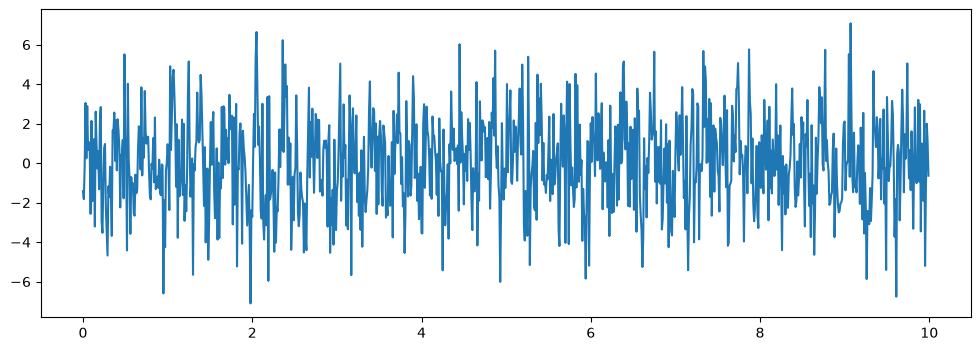

In [35]:
import numpy as np
import matplotlib.pyplot as plt

dt = 0.01
a = np.arange(0,10,dt)
noisy_signal = np.sin(2*np.pi*3*a) + np.sin(2*np.pi*6*a) + 2*np.random.randn(len(a))
clean_signal = np.sin(2*np.pi*3*a) + np.sin(2*np.pi*6*a)
plt.figure(figsize=(12,4))
plt.plot(a,noisy_signal)
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

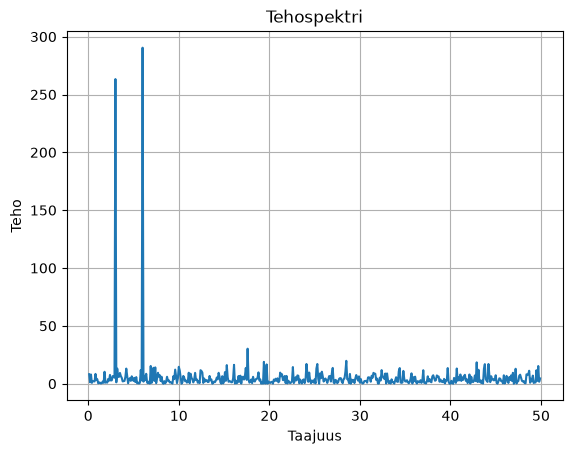

In [36]:
#Lasketaan signaalin fourier-muunno ja tehospektri
f = noisy_signal
N = len(f) #datapisteiden lukumäärä signaalissa
fourier = np.fft.fft(f,N) #Fourier muunnos, sisältää tiedon signaalin f sisältämistä taajuuksista
psd = fourier*np.conj(fourier)/N #Jokaisen rivin compleksiluvut kerrotaan kompleksikonjugaatillaan

freq = np.fft.fftfreq(N,dt)
L = np.arange(1, np.floor(N/2), dtype='int') #Rajataan pois negatiiviset taajuudet ja nollataajuus tehospektrin arvoista
PSD = np.array([freq[L], psd[L].real]) #Taajuudet ja tehospektrin arvot

plt.plot(PSD[0,:], PSD[1,:])
plt.title('Tehospektri')
plt.xlabel('Taajuus')
plt.ylabel('Teho')
plt.grid()
plt.show

#plt.plot(freq[1:len(psd)], psd[1:len(psd)].real)

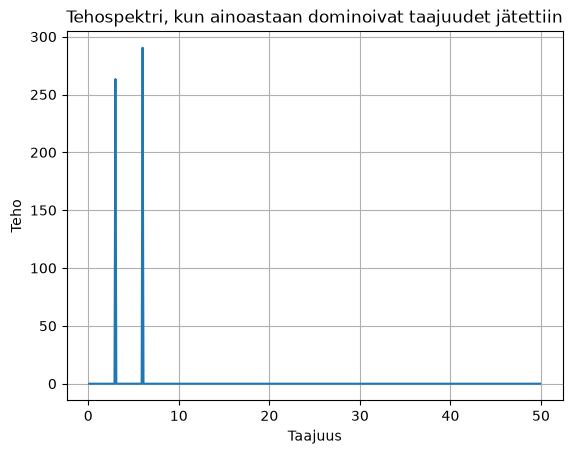

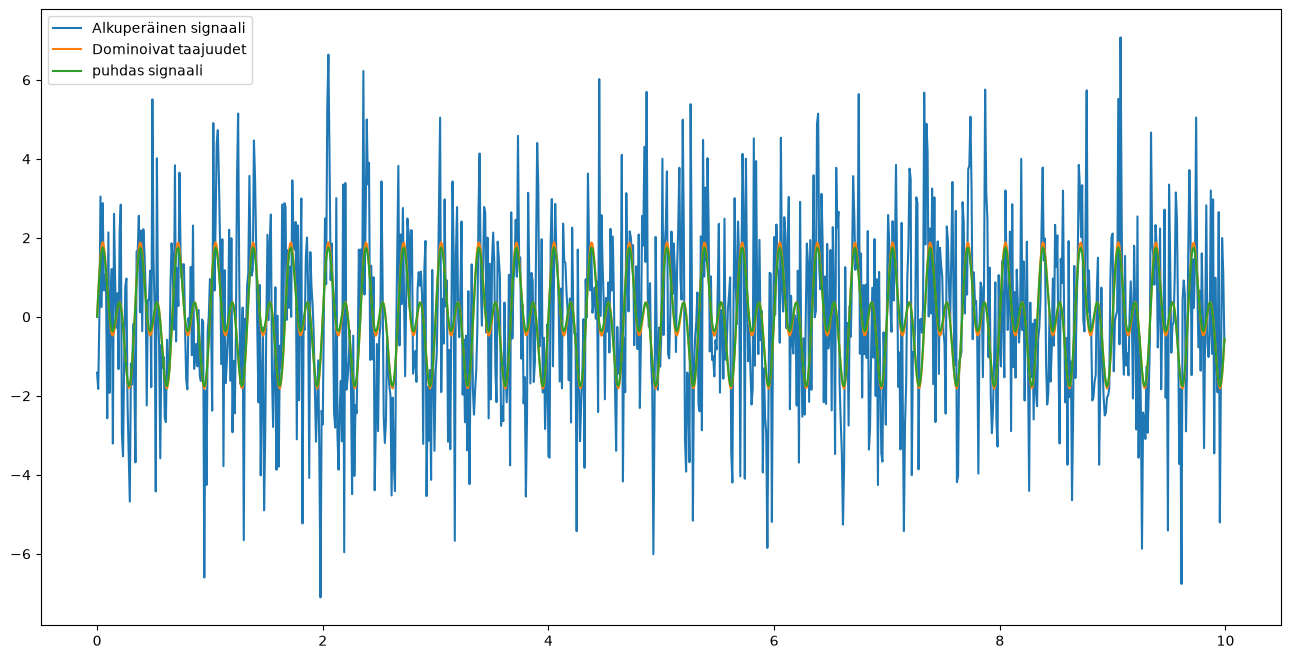

In [37]:
#Halutaan suodattaa pois tehospektrin pienemmät ja jättä jäljelle ainoastaan dominoivat taajuudet
fourier_dom = fourier.copy()
fourier_dom[psd<150] = 0
#testataan piirtämällä tehospektri
psd_dom = fourier*np.conj(fourier_dom)/N #Jokaisen rivin compleksiluvut kerrotaan kompleksikonjugaatillaan
PSD_dom = np.array([freq[L], psd_dom[L].real]) #Taajuudet ja tehospektrin arvot

plt.plot(PSD_dom[0,:], PSD_dom[1,:])
plt.title('Tehospektri, kun ainoastaan dominoivat taajuudet jätettiin')
plt.xlabel('Taajuus')
plt.ylabel('Teho')
plt.grid()
plt.show

#palautetaam signaali, jossa mukana ainoastaan dominoivat taajuudet
signal_dom = np.fft.ifft(fourier_dom).real

plt.figure(figsize=(16,8))
plt.plot(a,noisy_signal)
plt.plot(a,signal_dom)
plt.plot(a,clean_signal)
plt.legend(['Alkuperäinen signaali', 'Dominoivat taajuudet', 'puhdas signaali'])
plt.show()

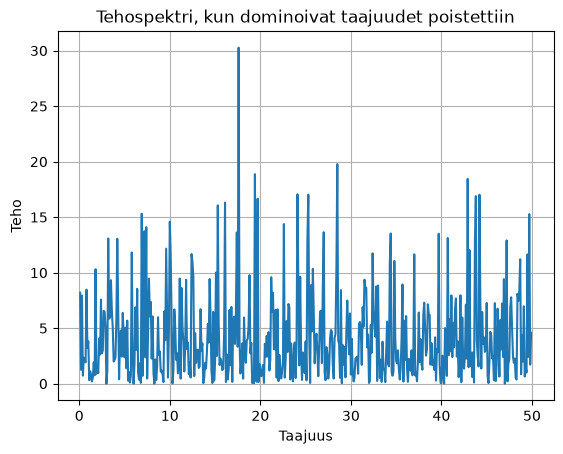

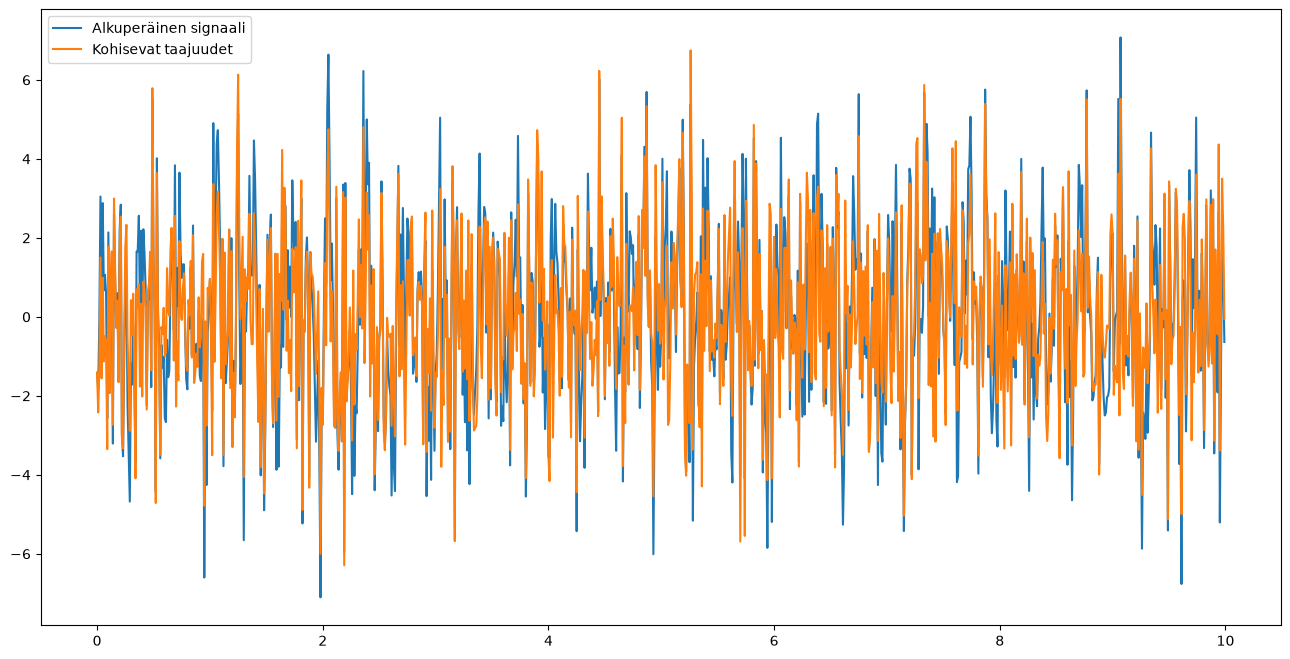

In [38]:
#Halutaan suodattaa pois tehospektrin pienemmät ja jättä jäljelle ainoastaan dominoivat taajuudet
fourier_noise = fourier.copy()
fourier_noise[psd>150] = 0
#testataan piirtämällä tehospektri
psd_noise = fourier*np.conj(fourier_noise)/N #Jokaisen rivin compleksiluvut kerrotaan kompleksikonjugaatillaan
PSD_noise = np.array([freq[L], psd_noise[L].real]) #Taajuudet ja tehospektrin arvot

plt.plot(PSD_noise[0,:], PSD_noise[1,:])
plt.title('Tehospektri, kun dominoivat taajuudet poistettiin')
plt.xlabel('Taajuus')
plt.ylabel('Teho')
plt.grid()
plt.show

#palautetaam signaali, jossa mukana ainoastaan dominoivat taajuudet
signal_noise = np.fft.ifft(fourier_noise).real

plt.figure(figsize=(16,8))
plt.plot(a,noisy_signal)
plt.plot(a,signal_noise)
plt.legend(['Alkuperäinen signaali', 'Kohisevat taajuudet',])
#plt.axis([0,2,-7,7])
plt.show()

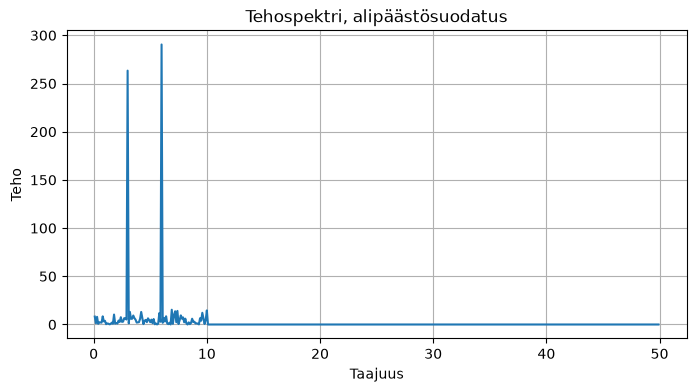

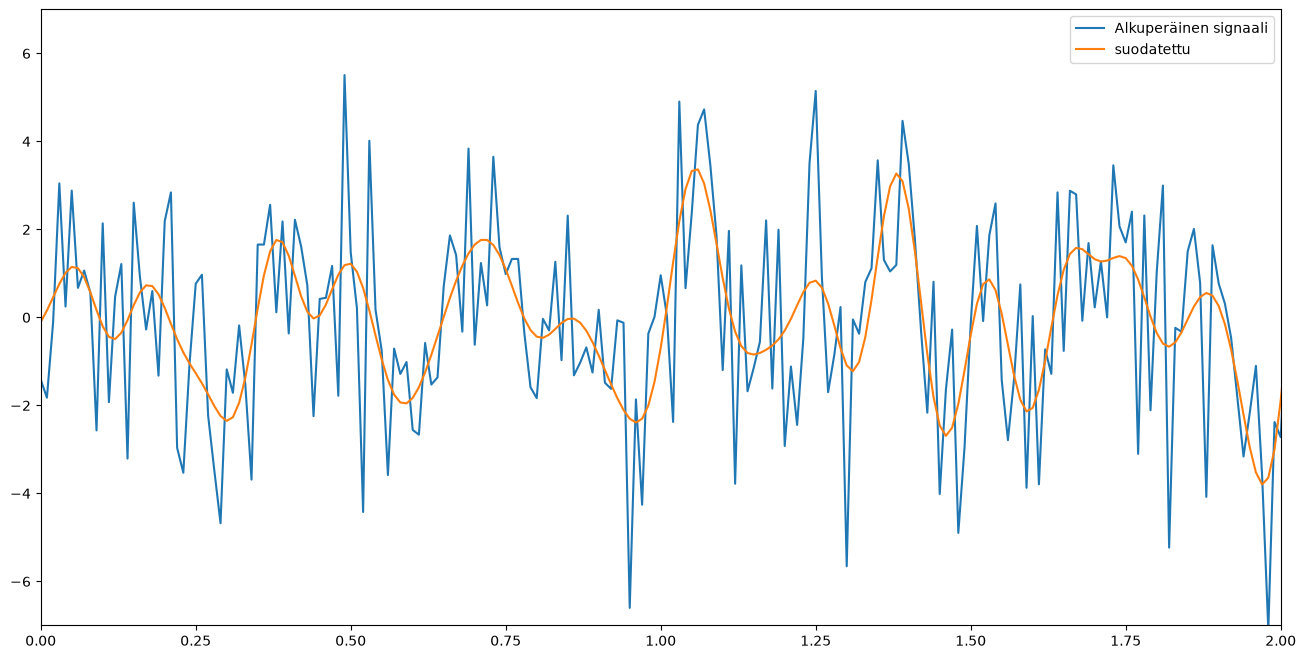

In [41]:
#kun halutaan suodattaa pois tietyt taajuuder:
fourier_filt = fourier.copy()
cutoff = 10
fourier_filt[np.abs(freq) > cutoff] = 0 #Alipäästösuodatin
#fourier_filt[np.abs(freq) < cutoff] = 0 #ylipäästösuodatin

# #testataan piirtämällä tehospektri
psd_filt = fourier*np.conj(fourier_filt)/N #Jokaisen rivin compleksiluvut kerrotaan kompleksikonjugaatillaan
PSD_filt = np.array([freq[L], psd_filt[L].real]) #Taajuudet ja tehospektrin arvot

plt.figure(figsize=(8,4))
plt.plot(PSD_filt[0,:], PSD_filt[1,:])
plt.title('Tehospektri, alipäästösuodatus')
plt.xlabel('Taajuus')
plt.ylabel('Teho')
plt.grid()
plt.show

# #palautetaan suodatettu signaali
signal_noise = np.fft.ifft(fourier_filt).real

plt.figure(figsize=(16,8))
plt.plot(a,noisy_signal)
plt.plot(a,signal_noise)
plt.legend(['Alkuperäinen signaali', 'suodatettu',])
plt.axis([0,2,-7,7])
plt.show()